## Clase 10 - Ejercicio: regresión sobre el dataset Swiss

**Joaquin Cernik**

Para aprender sobre regresión, vamos a utilizar un dataset clásico llamado Swiss, que proviene originalmente del lenguaje R. Este dataset contiene datos socioeconómicos de 47 provincias suizas a fines del siglo XIX. Cada fila representa una provincia, y las variables reflejan características demográficas y sociales relevantes para ese contexto histórico.

## Variables

- `Location`: Provincia donde se midieron los datos.
- `Fertility`: Tasa de fertilidad (número promedio de hijos por mujer)
- `Agriculture`:` Porcentaje de hombres ocupados en agricultura
- `Examination`: Porcentaje de hombres que completaron exámenes de educación superior
- `Education`: Nivel promedio de educación (escala arbitraria)
- `Catholic`: Porcentaje de población católica
- `Infant.Mortality`: Tasa de mortalidad infantil (por cada 1000 nacidos vivos)

## Que queremos predecir?

Vamos a utilizar este dataset para predecir la tasa de fertilidad en cada provincia mediante diferentes métodos de regresión.

--- 

Siguiendo el procedimiento típico de Machine Learning, vamos a leer los datos y separarlos en los datasets de entrenamiento y testeo utilizando Scikit-Learn...

In [15]:
import pandas as pd

df = pd.read_csv("swiss.csv")
dataset_sin_location = df.drop(columns=["Location"])
df.head()

,Location,Fertility,Agriculture,Examination,Education,Catholic,Infant.Mortality
0,Courtelary,80.2,17.0,15,12,9.96,22.2
1,Delemont,83.1,45.1,6,9,84.84,22.2
2,Franches-Mnt,92.5,39.7,5,5,93.40,20.2
3,Moutier,85.8,36.5,12,7,33.77,20.3
4,Neuveville,76.9,43.5,17,15,5.16,20.6


In [2]:
print(f"Tenemos {df.shape[0]} observaciones")

Tenemos 47 observaciones


Obtenemos la variable objetivo (`Fertility`) y, por otro lado, los atributos (quitamos `Location` ya que no es un atributo numérico relevante para la regresión)

In [3]:
X = df.drop(["Fertility", "Location"], axis=1)
y = df["Fertility"]

Dado que tenemos pocas observaciones, vamos a separar el dataset en un 50% para entrenamiento y 50% para testeo:

In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5, random_state=42)

## Regresión lineal múltiple

Arranquemos la primera parte del ejercicio. Para eso, vamos a entrenar un modelo de regresión lineal múltiple usando todos los atributos. Para ello debes:

1. Escalar los atributos usando `StandardScaler`
2. Entrenar el modelo usando el dataset de entrenamiento.
3. Obtener las predicciones sobre el dataset de testeo.
4. Calcular las métricas MAE, MSE  y $R^2$, e imprimir los resultados.

In [27]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, mean_absolute_percentage_error, root_mean_squared_error

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

##### COMPLETAR AQUI LO PEDIDO
#1 - escalamiento
numerical_columns_selected = ['Agriculture', 'Examination', 'Education', 'Catholic', 'Infant.Mortality']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_columns_selected)   
    ]
)

# Creamos el pipeline con preprocesamiento y modelo
pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())  # Aplicamos la regresión lineal
])



# 2 - Entrenamos el modelo
pipeline.fit(X_train, y_train)
# Resultados del entrenamiento:
print("-------------- ETAPA DE TRAINING ----------")
print("El valor de la intersección de la recta es "
f"{np.round(pipeline.named_steps['regressor'].intercept_, 2)}")
print("Los valores de los coeficientes de la recta son "
    f"{np.round(pipeline.named_steps['regressor'].coef_, 2)}")
print("El coeficiente de determinación (R^2) es " f"{round(pipeline.score(X_train, y_train), 2)}")

y_pred = pipeline.predict(X_train)
num_attributes = len(
    pipeline.named_steps['preprocessor'].get_feature_names_out())
varianza = np.sqrt((np.sum((y_train - y_pred)**2))/(y_train.size - num_attributes - 1))
print(f"Desvío estándar del modelo {round(varianza, 3)}")


# 3 - ETAPA DE TESTING
print("\n-------------- ETAPA DE TESTING ----------")
y_pred = pipeline.predict(X_test)

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = root_mean_squared_error(y_test, y_pred)
mape = mean_absolute_percentage_error(y_test, y_pred)

print("R-cuadrado en test:", round(r2, 3))
print("Error absoluto medio:", round(mae, 3))
print("Error cuadrático medio:", round(mse, 3))
print("Raíz de error cuadrático medio:", round(rmse, 3))
print(f"Error absoluto porcentual medio: {mape*100:.2f}%")

with open('modelo_inicial.pkl', 'wb') as archivo:
    joblib.dump(pipeline, archivo)


-------------- ETAPA DE TRAINING ----------
El valor de la intersección de la recta es 70.35
Los valores de los coeficientes de la recta son [-5.26  3.41 -9.93  7.97  3.58]
El coeficiente de determinación (R^2) es 0.67
Desvío estándar del modelo 8.319

-------------- ETAPA DE TESTING ----------
R-cuadrado en test: 0.574
Error absoluto medio: 6.094
Error cuadrático medio: 64.457
Raíz de error cuadrático medio: 8.029
Error absoluto porcentual medio: 8.48%


Vemos que el resultado es bastante malo, podemos decir a priori que es debido a que hay variables que estarian nublando y molestando a nuestro modelo

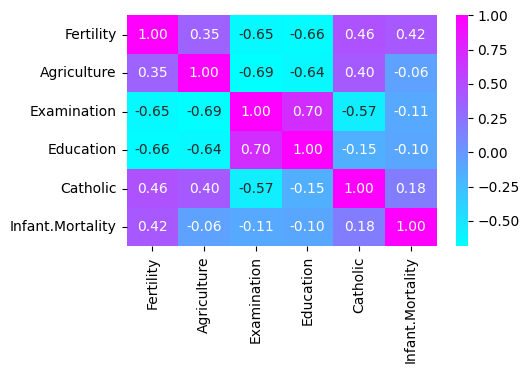

In [16]:
correlacion_profit = dataset_sin_location.corr()

plt.figure(figsize=(5, 3))
sns.heatmap(correlacion_profit, annot=True, cmap='cool', annot_kws={"size": 10}, 
    fmt=".2f", cbar=True)
plt.show()

De aqui podemos ver que existe una fuerte correlacion entre educatiom y examination, y agriculture y examination, por lo que podemos predecir que la variable examination desaparecera luego

## Modelo con regularización

Para mejorar nuestro modelo, vamos a explorar técnicas de regresión lineal con regularización, que nos permiten controlar el sobreajuste y seleccionar variables relevantes automáticamente.

Existen dos variantes muy populares:

- Una penaliza la suma de los cuadrados de los coeficientes (regularización L2).
- La otra penaliza la suma del valor absoluto de los coeficientes (regularización L1).

Ambas ayudan a mejorar la generalización, pero una de ellas además puede eliminar variables (coeficientes exactamente cero), lo que ayuda a identificar qué atributos son realmente importantes.

Tu tarea:

1. Elegí correctamente cuál de los dos métodos de regularización usar para este problema. 
    - Pista: Queremos que el modelo sea capaz de hacer una selección automática de variables, dejando fuera aquellas que no aportan.
2. Implementá un pipeline que incluya escalado y el modelo elegido.
3. Buscá automáticamente el mejor valor del hiperparámetro de regularización (alpha) usando validación cruzada usando 3-folds.
4. Entrená el modelo con los datos de entrenamiento y obtené las predicciones para el set de testeo.
5. Calcular las métricas MAE, MSE  y $R^2$, e imprimir los resultados.
6. Imprimí los coeficientes resultantes e identificá qué variables fueron eliminadas (coeficiente = 0).

In [17]:
import numpy as np

from sklearn.linear_model import LassoCV, RidgeCV

Paremos un momento para entender qué hacen LassoCV y RidgeCV antes de continuar con la resolución:

> Tanto `LassoCV` como `RidgeCV` son implementaciones de regresión lineal con regularización que incluyen la búsqueda automática del mejor hiperparámetro alpha mediante validación cruzada.
>
> Ambos métodos prueban distintos valores de alpha y eligen el que minimiza el error del modelo, facilitando el proceso de ajuste sin necesidad de una búsqueda manual.
>
> Internamente, utilizan la métrica del error cuadrático medio (MSE) para evaluar el rendimiento del modelo en cada fold de la validación cruzada.
>
> Por ejemplo, si llamás a RidgeCV(alphas=alphas, cv=5), se hará una validación cruzada de 5 folds utilizando los valores de alpha que vos le pases, y se seleccionará el que obtenga el menor MSE promedio.
> 
> Una vez elegido el mejor alpha, el modelo final se entrena con todos los datos de entrenamiento usando ese valor.

¡Listo! Con todo lo que vimos hasta ahora, ya estás en condiciones de resolver esta parte y completar los 6 puntos propuestos

In [25]:
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import KFold
from sklearn.linear_model import Lasso

def encontrar_alpha_optimo(X_train, y_train, alpha_array, kf):

# Donde vamos a almacenar los errores
    cv_lasso_errors = []

    # Búsqueda del mejor alpha usando un loop
    for alpha in alpha_array:
        fold_lasso_errors = []

        # Realizar la validación cruzada
        for train_idx, val_idx in kf.split(X_train):
            X_train_fold, X_val_fold = X_train.iloc[train_idx, :], \
                X_train.iloc[val_idx, :]
            y_train_fold, y_val_fold = y_train.iloc[train_idx], y_train.iloc[val_idx]
    
        # Crear y entrenar el modelo de lasso
            lasso = Lasso(alpha=alpha)
            if alpha == 0:
                lasso = LinearRegression()
        
            lasso.fit(X_train_fold, y_train_fold)

            # Hacer las predicciones sobre el fold de validación
            y_pred_lasso = lasso.predict(X_val_fold)

            # Calcular el error cuadrático medio para el fold
            mse_lasso = mean_absolute_error(y_val_fold, y_pred_lasso)
            fold_lasso_errors.append(mse_lasso)

        # Calcular el error medio para este alpha
        cv_lasso_errors.append(np.mean(fold_lasso_errors))

        # Mostramos cual es el mejor valor de alpha para cada caso
    best_alpha_lasso = alpha_array[np.argmin(cv_lasso_errors)]
    print(f"El mejor valor de alpha para Lasso es: {best_alpha_lasso}")
    return best_alpha_lasso

In [32]:
from sklearn.model_selection import KFold

alphas = np.logspace(-4, 1, 500)

##### COMPLETAR AQUI LO PEDIDO

# 1 - Calculo del mejor alpha
X_train_processed = preprocessor.fit_transform(X_train) # tengo que scalarlo primero
X_train_processed = pd.DataFrame(X_train_processed, columns=preprocessor.get_feature_names_out())

kf = KFold(n_splits=3, shuffle=True, random_state=42)
alpha_optimo_lasso = encontrar_alpha_optimo(X_train_processed, y_train, alphas, kf)

# 2 -  Armado del pipelina

pipeline_lasso = Pipeline(steps=[
    ('preprocessor', preprocessor), # usamos el preprocessor anterior
    ('regressor', Lasso(alpha=alpha_optimo_lasso))  # Aplicamos la regresión lineal
])

# 3 - Entrenamos el modelo
print("\n-------------- ETAPA DE TRAINING LASSO ----------")
pipeline_lasso.fit(X_train, y_train)

# Resultados del entrenamiento:
print("El valor de la intersección de la recta es "
f"{np.round(pipeline_lasso.named_steps['regressor'].intercept_, 2)}")
print("Los valores de los coeficientes de la recta son "
    f"{np.round(pipeline_lasso.named_steps['regressor'].coef_, 2)}")
print("El coeficiente de determinación (R^2) es " f"{round(pipeline_lasso.score(X_train, y_train), 2)}")

y_pred = pipeline_lasso.predict(X_train)
num_attributes = len(
    pipeline_lasso.named_steps['preprocessor'].get_feature_names_out())
varianza = np.sqrt((np.sum((y_train - y_pred)**2))/(y_train.size - num_attributes - 1))
print(f"Desvío estándar del modelo {round(varianza, 3)}")


# 4 - ETAPA DE TESTING
print("\n-------------- ETAPA DE TESTING LASSO ----------")
y_pred = pipeline_lasso.predict(X_test)

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = root_mean_squared_error(y_test, y_pred)
mape = mean_absolute_percentage_error(y_test, y_pred)

print("R-cuadrado en test:", round(r2, 3))
print("Error absoluto medio:", round(mae, 3))
print("Error cuadrático medio:", round(mse, 3))
print("Raíz de error cuadrático medio:", round(rmse, 3))
print(f"Error absoluto porcentual medio: {mape*100:.2f}%")

with open('modelo_lasso.pkl', 'wb') as archivo:
    joblib.dump(pipeline_lasso, archivo)

El mejor valor de alpha para Lasso es: 1.4398479528760066

-------------- ETAPA DE TRAINING LASSO ----------
El valor de la intersección de la recta es 70.35
Los valores de los coeficientes de la recta son [-0.   -1.01 -3.41  2.55  3.79]
El coeficiente de determinación (R^2) es 0.57
Desvío estándar del modelo 9.433

-------------- ETAPA DE TESTING LASSO ----------
R-cuadrado en test: 0.644
Error absoluto medio: 5.565
Error cuadrático medio: 53.95
Raíz de error cuadrático medio: 7.345
Error absoluto porcentual medio: 8.72%


In [33]:
X_train_processed.head(5)

,num__Agriculture,num__Examination,num__Education,num__Catholic,num__Infant.Mortality
0,-1.619194,-0.165703,0.166283,-0.895747,0.711590
1,1.675093,-1.118496,-0.624993,1.190891,0.023678
2,1.723610,-1.594892,-1.152511,1.191589,-1.323482
3,-0.731337,-0.880297,-0.493114,0.979018,1.972761
4,0.564060,0.548891,0.166283,-0.929237,-0.922200


Vemos que el coeficiente que se ha eliminado es el de `agriculture`, ya qye tiene el valor 0 en la primera posicion

## Comparación de modelos y conclusiones

Completá la siguiente tabla con las métricas obtenidas para cada uno de los modelos que entrenaste:

| Modelo                        | MAE | MSE | $R^2$ |
| ----------------------------- | --- | --- | ----- |
| Regresión Lineal              |6.094|64.457|0.574|
| Modelo Regularizado (L1)      |5.565|53.95|0.644|


> ⚠️ Asegurate de cambiar el nombre del modelo `Modelo Regularizado (L1 o L2)` según el modelo que usaste (Lasso o Ridge).

### Justificación

**¿Cuál de los modelos te parece que tuvo un mejor desempeño general?**

Tené en cuenta las tres métricas al responder, y también pensá en la complejidad del modelo (por ejemplo, si eliminó variables innecesarias).

Escribí tu respuesta a continuación:

ESCRIBA AQUI SU RESPUESTA

El Modelo Regularizado Lasso tuvo un desempeño claramente superior en comparación con la Regresión Lineal tradicional. Las razones principales que justifican esto son:  

* `Mejora en todas las métricas de error:` Lasso logró reducir tanto el MAE (bajo de $6.094$ a $5.565$) como el MSE (bajo de $64.457$ a $53.95$) en el conjunto de prueba.   

* `Mayor capacidad explicativa ($R^2$):` 
.El coeficiente de determinación aumentó de $0.574$ a $0.644$, lo que significa que el modelo regularizado explica un $64.4\%$ de la variabilidad en los datos de prueba, frente al $57.4\%$ de la regresión lineal simple.   

* `Reducción de complejidad y selección de variables:` Gracias a la penalización L1, Lasso eliminó la variable redundante (Agriculture quedó con coeficiente $0.0$). Esto simplificó el modelo, atenuó la multicolinealidad con Education y Examination, y previno el sobreajuste (overfitting), logrando un modelo más interpretable y con mejor poder de generalización. 